In [1]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
from sklearn.preprocessing import StandardScaler 
import warnings
warnings.filterwarnings("ignore")

## Carregando os dados

In [2]:
df_dsa = pd.read_csv('dataset.csv')

In [3]:
df_dsa.shape

(2938, 22)

In [4]:
df_dsa.dtypes

Country                             object
Year                                 int64
Status                              object
Life expectancy                    float64
Adult Mortality                    float64
infant deaths                        int64
Alcohol                            float64
percentage expenditure             float64
Hepatitis B                        float64
Measles                              int64
 BMI                               float64
under-five deaths                    int64
Polio                              float64
Total expenditure                  float64
Diphtheria                         float64
 HIV/AIDS                          float64
GDP                                float64
 Population                        float64
 thinness  1-19 years              float64
 thinness 5-9 years                float64
Income composition of resources    float64
Schooling                          float64
dtype: object

In [5]:
df_dsa.sample(10)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
151,Azerbaijan,2008,Developing,73.0,141.0,6,1.18,206.261613,68.0,5,...,85.0,4.37,81.0,0.1,5574.638200,87634.0,2.8,2.9,0.719,11.6
539,Chad,2004,Developing,48.5,45.0,44,0.34,72.384513,NaN,10324,...,31.0,5.72,21.0,5.2,454.676588,97143.0,1.7,1.6,0.301,5.6
357,Brazil,2010,Developing,73.8,154.0,54,7.52,1111.191325,96.0,68,...,99.0,8.27,99.0,0.1,11224.154800,196796269.0,2.9,2.9,0.716,13.8
231,Belarus,2008,Developing,70.0,224.0,1,14.67,501.805614,98.0,0,...,98.0,5.95,97.0,0.1,6376.183153,9527985.0,2.1,2.3,0.755,15.1
2663,Trinidad and Tobago,2001,Developing,69.1,194.0,0,4.55,516.711248,NaN,0,...,91.0,4.40,91.0,1.2,6935.721451,127238.0,6.6,7.1,0.715,11.8
901,Fiji,2012,Developing,69.4,195.0,0,0.01,431.485487,99.0,0,...,99.0,4.16,99.0,0.1,4546.738540,873596.0,4.0,3.7,0.714,14.9
1901,Nigeria,2007,Developing,55.0,388.0,542,9.55,104.474644,42.0,2613,...,54.0,4.47,42.0,5.2,1136.829645,14641724.0,12.3,12.3,0.477,9.1
2515,Sweden,2005,Developed,85.0,66.0,0,6.50,599.039240,NaN,13,...,98.0,9.60,98.0,0.1,4385.353150,929572.0,1.3,1.3,0.890,16.0
805,Egypt,2012,Developing,72.0,165.0,54,0.23,0.000000,93.0,245,...,93.0,5.29,93.0,0.1,NaN,NaN,2.9,2.8,0.673,12.4
422,Burundi,2009,Developing,56.2,338.0,23,4.05,2.030495,94.0,305,...,96.0,6.96,94.0,2.4,24.944652,848931.0,7.8,7.8,0.336,8.6


## Ajustes iniciais nos dados

In [6]:
# Criando um novo dataset e ajustando o nome das variáveis
# Observe que estamos desconsiderando algumas variáveis:
# percentage expenditure, under-five deaths e Income composition of resources não estão sendo consideradas
# Essas variáveis não apresentam descrição clara na fonte de dados e por isso estão sendo removidas da análise
df = pd.DataFrame({'country': df_dsa['Country'],
                   'life_expectancy': df_dsa['Life expectancy '],
                   'year': df_dsa['Year'],
                   'status': df_dsa['Status'],
                   'adult_mortality': df_dsa['Adult Mortality'],
                   'inf_death': df_dsa['infant deaths'],
                   'alcohol': df_dsa['Alcohol'],
                   'hepatitisB': df_dsa['Hepatitis B'],
                   'measles': df_dsa['Measles '],
                   'bmi': df_dsa[' BMI '],
                   'polio': df_dsa['Polio'],
                   'diphtheria': df_dsa['Diphtheria '],
                   'hiv': df_dsa[' HIV/AIDS'],
                   'gdp': df_dsa['GDP'],
                   'total_expenditure': df_dsa['Total expenditure'],
                   'thinness_till19': df_dsa[' thinness  1-19 years'],
                   'thinness_till9': df_dsa[' thinness 5-9 years'],
                   'school': df_dsa['Schooling'],
                   'population': df_dsa[' Population']})

In [7]:
df.shape

(2938, 19)

In [8]:
df.head()

,country,life_expectancy,year,status,adult_mortality,inf_death,alcohol,hepatitisB,measles,bmi,polio,diphtheria,hiv,gdp,total_expenditure,thinness_till19,thinness_till9,school,population
0,Afghanistan,65.0,2015,Developing,263.0,62,0.01,65.0,1154,19.1,6.0,65.0,0.1,584.259210,8.16,17.2,17.3,10.1,33736494.0
1,Afghanistan,59.9,2014,Developing,271.0,64,0.01,62.0,492,18.6,58.0,62.0,0.1,612.696514,8.18,17.5,17.5,10.0,327582.0
2,Afghanistan,59.9,2013,Developing,268.0,66,0.01,64.0,430,18.1,62.0,64.0,0.1,631.744976,8.13,17.7,17.7,9.9,31731688.0
3,Afghanistan,59.5,2012,Developing,272.0,69,0.01,67.0,2787,17.6,67.0,67.0,0.1,669.959000,8.52,17.9,18.0,9.8,3696958.0
4,Afghanistan,59.2,2011,Developing,275.0,71,0.01,68.0,3013,17.2,68.0,68.0,0.1,63.537231,7.87,18.2,18.2,9.5,2978599.0


## Análise exploratória 

In [9]:
# Cria um dicionário com a descrição de cada variável
dsa_df_dict = {
    "country": "País de origem dos dados.",
    "life_expectancy": "Expectativa de vida ao nascer, em anos.",
    "year": "Ano em que os dados foram coletados.",
    "status": "Status de desenvolvimento do país ('Developing' para países em desenvolvimento, 'Developed' para países desenvolvidos).",
    "adult_mortality": "Taxa de mortalidade de adultos entre 15 e 60 anos por 1000 habitantes.",
    "inf_death": "Número de mortes de crianças com menos de 5 anos por 1000 nascidos vivos.",
    "alcohol": "Consumo de álcool per capita (litros de álcool puro por ano).",
    "hepatitisB": "Cobertura de vacinação contra hepatite B em crianças de 1 ano (%).",
    "measles": "Número de casos de sarampo relatados por 1000 habitantes.",
    "bmi": "Índice médio de massa corporal da população adulta.",
    "polio": "Cobertura de vacinação contra poliomielite em crianças de 1 ano (%).",
    "diphtheria": "Cobertura de vacinação contra difteria, tétano e coqueluche (DTP3) em crianças de 1 ano (%).",
    "hiv": "Prevalência de HIV na população adulta (%).",
    "gdp": "Produto Interno Bruto per capita (em dólares americanos).",
    "total_expenditure": "Gasto total em saúde como porcentagem do PIB.",
    "thinness_till19": "Prevalência de magreza em crianças e adolescentes de 10 a 19 anos (%).",
    "thinness_till9": "Prevalência de magreza em crianças de 5 a 9 anos (%).",
    "school": "Número médio de anos de escolaridade.",
    "population": "População total do país."
}

In [10]:
# Agora é só consultar sempre que tiver dúvidas sobre cada variável
dsa_df_dict['life_expectancy']

'Expectativa de vida ao nascer, em anos.'

<Axes: >

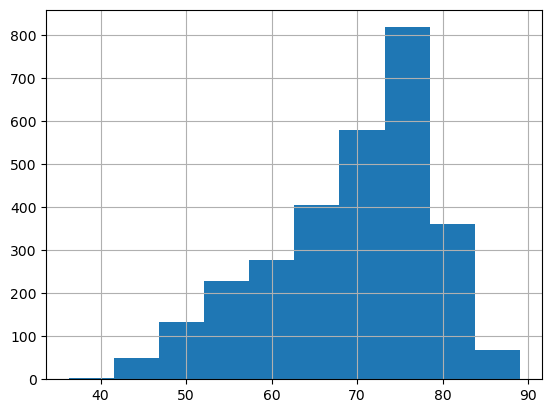

In [11]:
#plot do histograma da variável alvo (variável quantitativa)
df['life_expectancy'].hist()

In [12]:
#resumo estatistico (somente com variáveis númericas)
df.describe()

,life_expectancy,year,adult_mortality,inf_death,alcohol,hepatitisB,measles,bmi,polio,diphtheria,hiv,gdp,total_expenditure,thinness_till19,thinness_till9,school,population
count,2928.000000,2938.000000,2928.000000,2938.000000,2744.000000,2385.000000,2938.000000,2904.000000,2919.000000,2919.000000,2938.000000,2490.000000,2712.00000,2904.000000,2904.000000,2775.000000,2.286000e+03
mean,69.224932,2007.518720,164.796448,30.303948,4.602861,80.940461,2419.592240,38.321247,82.550188,82.324084,1.742103,7483.158469,5.93819,4.839704,4.870317,11.992793,1.275338e+07
std,9.523867,4.613841,124.292079,117.926501,4.052413,25.070016,11467.272489,20.044034,23.428046,23.716912,5.077785,14270.169342,2.49832,4.420195,4.508882,3.358920,6.101210e+07
min,36.300000,2000.000000,1.000000,0.000000,0.010000,1.000000,0.000000,1.000000,3.000000,2.000000,0.100000,1.681350,0.37000,0.100000,0.100000,0.000000,3.400000e+01
25%,63.100000,2004.000000,74.000000,0.000000,0.877500,77.000000,0.000000,19.300000,78.000000,78.000000,0.100000,463.935626,4.26000,1.600000,1.500000,10.100000,1.957932e+05
50%,72.100000,2008.000000,144.000000,3.000000,3.755000,92.000000,17.000000,43.500000,93.000000,93.000000,0.100000,1766.947595,5.75500,3.300000,3.300000,12.300000,1.386542e+06
75%,75.700000,2012.000000,228.000000,22.000000,7.702500,97.000000,360.250000,56.200000,97.000000,97.000000,0.800000,5910.806335,7.49250,7.200000,7.200000,14.300000,7.420359e+06
max,89.000000,2015.000000,723.000000,1800.000000,17.870000,99.000000,212183.000000,87.300000,99.000000,99.000000,50.600000,119172.741800,17.60000,27.700000,28.600000,20.700000,1.293859e+09


In [13]:
# Função para o plot da relação da variável alvo com alguns atributos
def dsa_get_pairs(data, alvo, atributos, n):
    
    # Grupos de linhas com 3 (n) gráficos por linha
    grupos_linhas = [atributos[i:i+n] for i in range(0, len(atributos), n)]

    # Loop pelos grupos de linhas para criar cada pair plot
    for linha in grupos_linhas:
        plot = sns.pairplot(x_vars = linha, y_vars = alvo, data = data, kind = "reg", height = 3)

    return

In [14]:
# Variável alvo
alvo = ['life_expectancy']

In [15]:
# Vamos usar alguns atributos
atributos = ['population', 'hepatitisB', 'gdp', 'total_expenditure', 'alcohol', 'school'] 

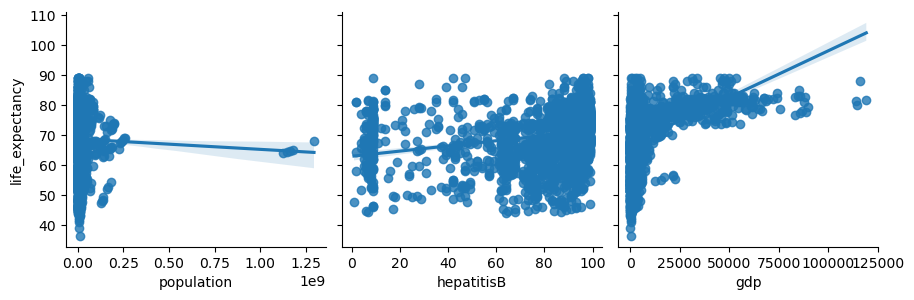

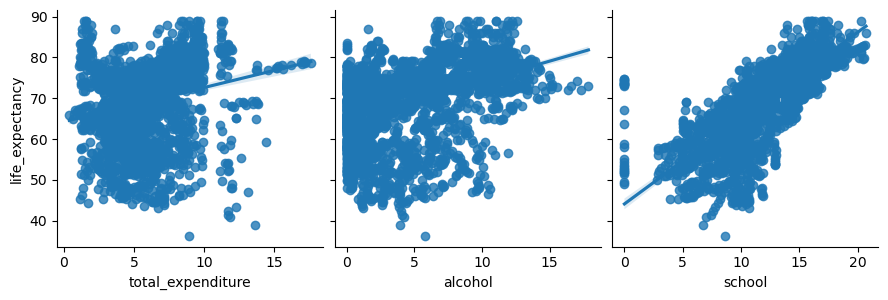

In [16]:
# Verificando outliers
dsa_get_pairs(df, alvo, atributos, 3)

## Detectando valores ausentes

In [17]:
# Visualizando o total de linhas por coluna
df.count()

country              2938
life_expectancy      2928
year                 2938
status               2938
adult_mortality      2928
inf_death            2938
alcohol              2744
hepatitisB           2385
measles              2938
bmi                  2904
polio                2919
diphtheria           2919
hiv                  2938
gdp                  2490
total_expenditure    2712
thinness_till19      2904
thinness_till9       2904
school               2775
population           2286
dtype: int64

In [18]:
valores_ausentes = df.isnull().sum().sort_values(ascending= False)

In [19]:
valores_ausentes

population           652
hepatitisB           553
gdp                  448
total_expenditure    226
alcohol              194
school               163
bmi                   34
thinness_till19       34
thinness_till9        34
diphtheria            19
polio                 19
life_expectancy       10
adult_mortality       10
year                   0
country                0
measles                0
inf_death              0
status                 0
hiv                    0
dtype: int64

In [20]:
valores_ausentes_percent = valores_ausentes[valores_ausentes > 0 ] / df.shape[0]

In [21]:
valores_ausentes_percent

population           0.221920
hepatitisB           0.188223
gdp                  0.152485
total_expenditure    0.076923
alcohol              0.066031
school               0.055480
bmi                  0.011572
thinness_till19      0.011572
thinness_till9       0.011572
diphtheria           0.006467
polio                0.006467
life_expectancy      0.003404
adult_mortality      0.003404
dtype: float64

In [22]:
print(f"O valor dos valores ausentes em % é de: \n {valores_ausentes_percent * 100}")

O valor dos valores ausentes em % é de: 
 population           22.191967
hepatitisB           18.822328
gdp                  15.248468
total_expenditure     7.692308
alcohol               6.603131
school                5.547992
bmi                   1.157250
thinness_till19       1.157250
thinness_till9        1.157250
diphtheria            0.646698
polio                 0.646698
life_expectancy       0.340368
adult_mortality       0.340368
dtype: float64


## Detectando outliers
vamos começar olhando para as variaveis que tem o maior percentual de valores ausentes

In [23]:
#atributos com mais de 5% de valores null
atributos = ['population', 'hepatitisB', 'gdp', 'total_expenditure', 'alcohol', 'school']

In [24]:
#cria um novo df para realizarmos consultas e testes
novo_df = df[atributos]

In [25]:
# identificação de outliers atraves do método de IQR
Q1 = novo_df.quantile(0.25)
Q3 = novo_df.quantile(0.75)
IQR = Q3 - Q1

In [26]:
#definir outliers como aqueles valores que estão fora do intervalo [ Q1 - 1.5 * IQR, Q3 +1,5 * IQR]
outliers = ((novo_df < ( Q1 - 1.5 * IQR)) | (novo_df > (Q3 + 1.5 * IQR))).sum()

In [27]:
outliers

population           294
hepatitisB           254
gdp                  365
total_expenditure     32
alcohol                0
school                44
dtype: int64

In [28]:
#criando um resumo com os outliers
outliers_summary = pd.DataFrame({'Outliers' : outliers, 'Percentual' : (outliers / len(novo_df)) * 100})

In [29]:
outliers_summary

,Outliers,Percentual
population,294,10.006807
hepatitisB,254,8.645337
gdp,365,12.423417
total_expenditure,32,1.089176
alcohol,0,0.000000
school,44,1.497617


## Análise estatistica para tratamentos de outliers

In [30]:
# definindo os limites para filtrar os outliers
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

In [31]:
novo_df_2 = df[~((novo_df < limite_inferior) | (novo_df > limite_superior)).any(axis=1)]

In [32]:
novo_df_2.shape

(2044, 19)

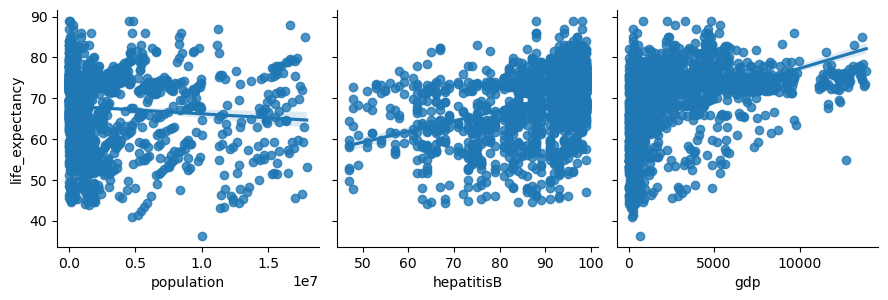

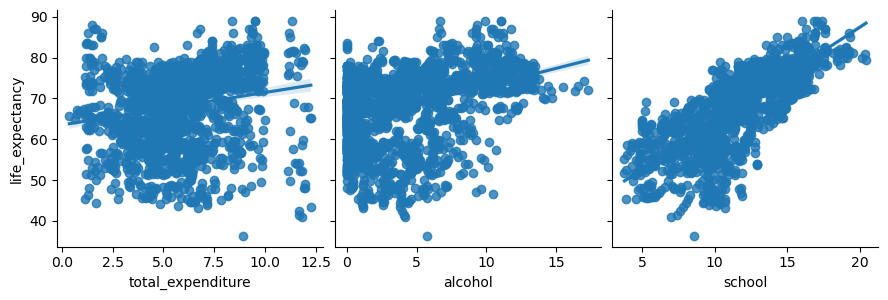

In [33]:
dsa_get_pairs(novo_df_2, alvo, atributos, 3)

## analise estatistica para tratamento de valores ausentes

In [34]:
#verificando o total de valores ausentes
valores_ausentes = novo_df_2.isnull().sum().sort_values(ascending=False)

In [35]:
#checando percentual
valores_ausentes_percent = valores_ausentes[valores_ausentes > 0] / novo_df_2.shape[0]
print(f'{valores_ausentes_percent * 100} %')

population           24.168297
hepatitisB           19.129159
gdp                  18.395303
total_expenditure     7.876712
alcohol               6.653620
school                6.555773
bmi                   0.587084
thinness_till19       0.587084
thinness_till9        0.587084
life_expectancy       0.391389
adult_mortality       0.391389
diphtheria            0.146771
polio                 0.146771
dtype: float64 %


In [36]:
def impute_median(dados):
    return dados.fillna(dados.median())

In [37]:
# Removendo valores missing
novo_df_2.loc[:,'population'] = novo_df_2['population'].transform(impute_median)
novo_df_2.hepatitisB = novo_df_2['hepatitisB'].transform(impute_median)
novo_df_2.alcohol = novo_df_2['alcohol'].transform(impute_median)
novo_df_2.total_expenditure = novo_df_2['total_expenditure'].transform(impute_median)
novo_df_2.gdp = novo_df_2['gdp'].transform(impute_median)
novo_df_2.school = novo_df_2['school'].transform(impute_median)

In [38]:
# Verificando o total de valores ausentes
valores_ausentes = novo_df_2.isnull().sum().sort_values(ascending = False)

In [39]:
# Checando percentual de valores missing
valores_ausentes_percent = valores_ausentes[valores_ausentes > 0] / novo_df_2.shape[0] 
print(f'{valores_ausentes_percent * 100} %')

thinness_till19    0.587084
thinness_till9     0.587084
bmi                0.587084
life_expectancy    0.391389
adult_mortality    0.391389
polio              0.146771
diphtheria         0.146771
dtype: float64 %


In [40]:
novo_df_2.dropna(inplace= True)

In [41]:
# Verificando o total de valores ausentes
valores_ausentes = novo_df_2.isnull().sum().sort_values(ascending = False)

In [42]:
# Checando percentual de valores missing
valores_ausentes_percent = valores_ausentes[valores_ausentes > 0] / novo_df_2.shape[0] 
print(f'{valores_ausentes_percent * 100} %')

Series([], dtype: float64) %


In [43]:
novo_df_2.drop(['country', 'status'], axis= 1, inplace=True)

## engenharia de recursos
    Como há diferença mt grande de população entre os países, usar essa variavel pode ser arriscado. vamos criar uma nova variavel e categorizar os paises em uma de 3 faixas possíveis de população

In [44]:
novo_df_2.population.min()

34.0

In [45]:
novo_df_2.population.max()

17899562.0

In [46]:
#criando os pontos de cortes (cutoff) com 2 percentis como referencia
pontos_corte = [novo_df_2.population.quantile(0.33), novo_df_2.population.quantile(0.67)]

In [47]:
pontos_corte

[np.float64(656519.86), np.float64(1365811.6)]

In [48]:
#criando uma nova variavel com todos os valores preenchidos com 1 
novo_df_2['pop_size'] = 1

In [49]:
# definindo a faixa onde a variavel terá o valor 2 
novo_df_2.loc[(novo_df_2.population < pontos_corte[1]) & (novo_df_2.population > pontos_corte[0]), 'pop_size'] = 2

In [50]:
# definindo a faixa onde a variavel terá o valor 3 
novo_df_2.loc[(novo_df_2.population >= pontos_corte[1]), 'pop_size'] = 3

In [51]:
novo_df_2.pop_size.value_counts()

pop_size
2    687
1    668
3    668
Name: count, dtype: int64

In [52]:
#criando uma nova variavel

"""
a variável bmi e alchool tem uma ligação direta, uma traz o consumo de cada pais e uma o indice de massa corporal (imc no brasil). então há uma relação entre essas variáveis 
"""

novo_df_2['lifestyle'] = 0 
novo_df_2.lifestyle = novo_df_2['bmi'] * novo_df_2['alcohol']

In [53]:
novo_df_2.head()

,life_expectancy,year,adult_mortality,inf_death,alcohol,hepatitisB,measles,bmi,polio,diphtheria,hiv,gdp,total_expenditure,thinness_till19,thinness_till9,school,population,pop_size,lifestyle
1,59.9,2014,271.0,64,0.01,62.0,492,18.6,58.0,62.0,0.1,612.696514,8.18,17.5,17.5,10.0,327582.0,1,0.186
3,59.5,2012,272.0,69,0.01,67.0,2787,17.6,67.0,67.0,0.1,669.959000,8.52,17.9,18.0,9.8,3696958.0,3,0.176
4,59.2,2011,275.0,71,0.01,68.0,3013,17.2,68.0,68.0,0.1,63.537231,7.87,18.2,18.2,9.5,2978599.0,3,0.172
5,58.8,2010,279.0,74,0.01,66.0,1989,16.7,66.0,66.0,0.1,553.328940,9.20,18.4,18.4,9.2,2883167.0,3,0.167
6,58.6,2009,281.0,77,0.01,63.0,2861,16.2,63.0,63.0,0.1,445.893298,9.42,18.6,18.7,8.9,284331.0,1,0.162


In [54]:
novo_df_2.lifestyle.describe()

count    2023.000000
mean      178.996408
std       209.416553
min         0.018000
25%        18.140500
50%        95.323000
75%       257.394000
max      1036.869000
Name: lifestyle, dtype: float64

In [55]:
#verificando valores ausentes
missing_values = novo_df_2.isnull().sum().sort_values(ascending = False)
missing_values

life_expectancy      0
year                 0
adult_mortality      0
inf_death            0
alcohol              0
hepatitisB           0
measles              0
bmi                  0
polio                0
diphtheria           0
hiv                  0
gdp                  0
total_expenditure    0
thinness_till19      0
thinness_till9       0
school               0
population           0
pop_size             0
lifestyle            0
dtype: int64

## Análise de Correlação Para Verificar Multicolinearidade

Queremos que as variáveis preditoras tenham uma alta correlação com a variável alvo, mas não queremos que as variáveis preditoras tenham alta correlação entre si. Se houver alta correlação entre as variáveis preditoras isso é chamado de multicolinearidade e fere uma das suposições da regressão.

A correlação é uma medida da relação entre as variáveis. O coeficiente de correlação é um valor de -1 a +1, sendo:

**-1 indica alta correlação negativa.**

**+1 indica ata correlação positiva.**

**0 indica que não há correlação.**

Correlação não implica causalidade. Por exemplo: Sempre que aumenta o consumo de sorvete aumenta a presença de tubarões na praia. Provavelmente ambos os eventos ocorrem no verão e estão correlacionados, mas isso não significa que um evento causa o outro. Para afirmar isso teríamos que fazer uma análise de causalidade.

In [56]:
novo_df_2.corr()

,life_expectancy,year,adult_mortality,inf_death,alcohol,hepatitisB,measles,bmi,polio,diphtheria,hiv,gdp,total_expenditure,thinness_till19,thinness_till9,school,population,pop_size,lifestyle
life_expectancy,1.000000,0.204556,-0.658916,-0.206443,0.342425,0.257860,-0.115350,0.557954,0.452564,0.483659,-0.573127,0.360736,0.175738,-0.433580,-0.429357,0.708272,-0.105317,-0.117333,0.441366
year,0.204556,1.000000,-0.091760,-0.059838,-0.066639,-0.003178,-0.064347,0.096763,0.147489,0.228939,-0.158820,0.170945,0.070267,-0.059353,-0.055950,0.219471,0.020981,0.013190,-0.017373
adult_mortality,-0.658916,-0.091760,1.000000,0.099370,-0.149204,-0.188950,0.035432,-0.366745,-0.228938,-0.221803,0.512978,-0.197863,-0.090963,0.299104,0.302507,-0.383901,0.096768,0.123785,-0.231128
inf_death,-0.206443,-0.059838,0.099370,1.000000,-0.127545,-0.122515,0.480129,-0.221948,-0.183569,-0.183910,0.039115,-0.120331,-0.121871,0.321487,0.354512,-0.214215,0.111901,0.111776,-0.156769
alcohol,0.342425,-0.066639,-0.149204,-0.127545,1.000000,0.193844,-0.045324,0.310448,0.187916,0.199958,-0.036268,0.289360,0.262657,-0.386629,-0.379482,0.464657,-0.007040,0.002445,0.878858
hepatitisB,0.257860,-0.003178,-0.188950,-0.122515,0.193844,1.000000,-0.043089,0.115409,0.393191,0.391270,-0.090390,0.167829,0.046093,-0.086406,-0.102546,0.263879,-0.056455,-0.028477,0.181579
measles,-0.115350,-0.064347,0.035432,0.480129,-0.045324,-0.043089,1.000000,-0.142187,-0.110853,-0.123043,0.024412,-0.065666,-0.101675,0.133515,0.137056,-0.089084,-0.005326,0.017013,-0.085123
bmi,0.557954,0.096763,-0.366745,-0.221948,0.310448,0.115409,-0.142187,1.000000,0.253961,0.273612,-0.244626,0.323198,0.200959,-0.541904,-0.550691,0.552766,-0.056945,-0.041854,0.599062
polio,0.452564,0.147489,-0.228938,-0.183569,0.187916,0.393191,-0.110853,0.253961,1.000000,0.676507,-0.143756,0.198453,0.141294,-0.166819,-0.166363,0.382712,-0.045542,-0.041742,0.219793
diphtheria,0.483659,0.228939,-0.221803,-0.183910,0.199958,0.391270,-0.123043,0.273612,0.676507,1.000000,-0.154179,0.222266,0.157976,-0.189487,-0.186992,0.430627,-0.035142,-0.035290,0.225132


In [57]:
#filtrando a matriz de correlação
dfCorr = novo_df_2.corr()
df_filtro_1 = dfCorr[((dfCorr >= 0.3) | (dfCorr <= -0.3)) & (dfCorr != 1.000000)]
df_filtro_1

,life_expectancy,year,adult_mortality,inf_death,alcohol,hepatitisB,measles,bmi,polio,diphtheria,hiv,gdp,total_expenditure,thinness_till19,thinness_till9,school,population,pop_size,lifestyle
life_expectancy,NaN,NaN,-0.658916,NaN,0.342425,NaN,NaN,0.557954,0.452564,0.483659,-0.573127,0.360736,NaN,-0.433580,-0.429357,0.708272,NaN,NaN,0.441366
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adult_mortality,-0.658916,NaN,NaN,NaN,NaN,NaN,NaN,-0.366745,NaN,NaN,0.512978,NaN,NaN,NaN,0.302507,-0.383901,NaN,NaN,NaN
inf_death,NaN,NaN,NaN,NaN,NaN,NaN,0.480129,NaN,NaN,NaN,NaN,NaN,NaN,0.321487,0.354512,NaN,NaN,NaN,NaN
alcohol,0.342425,NaN,NaN,NaN,NaN,NaN,NaN,0.310448,NaN,NaN,NaN,NaN,NaN,-0.386629,-0.379482,0.464657,NaN,NaN,0.878858
hepatitisB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.393191,0.391270,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
measles,NaN,NaN,NaN,0.480129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,0.557954,NaN,-0.366745,NaN,0.310448,NaN,NaN,NaN,NaN,NaN,NaN,0.323198,NaN,-0.541904,-0.550691,0.552766,NaN,NaN,0.599062
polio,0.452564,NaN,NaN,NaN,NaN,0.393191,NaN,NaN,NaN,0.676507,NaN,NaN,NaN,NaN,NaN,0.382712,NaN,NaN,NaN
diphtheria,0.483659,NaN,NaN,NaN,NaN,0.391270,NaN,NaN,0.676507,NaN,NaN,NaN,NaN,NaN,NaN,0.430627,NaN,NaN,NaN


As variáveis adult_mortality, alcohol, bmi, polio, diphtheria, hiv, gdp, thinness_till19, thinness_till9, school e lifestyle atendem ao nosso critério. São as variáveis preditoras com maior correlação com a variável alvo.

Agora devemos checar uma das suposições da Regressão Linear e identificar possíveis problemas de multicolinearidade (alta correlação entre as variáveis preditoras). Com base nesse critério eliminamos uma de duas variáveis preditoras altamente correlacionadas. Vamos considerar 0.65 como marca de corte. Vamos filtrar mais uma vez a matriz de correlação.

In [58]:
#filtrando a matriz de correlação
dfCorr = novo_df_2.corr()
df_filtro_2 = dfCorr[((dfCorr >= 0.65) | (dfCorr <= -0.65)) & (dfCorr != 1.000)]
df_filtro_2 = df_filtro_2.drop('life_expectancy', axis= 1)
df_filtro_2 = df_filtro_2.drop('life_expectancy', axis= 0)
df_filtro_2

,year,adult_mortality,inf_death,alcohol,hepatitisB,measles,bmi,polio,diphtheria,hiv,gdp,total_expenditure,thinness_till19,thinness_till9,school,population,pop_size,lifestyle
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adult_mortality,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inf_death,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alcohol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.878858
hepatitisB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
measles,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
polio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.676507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diphtheria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.676507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hiv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Decisão

**Primeiro Filtro - Correlação com a Variável Alvo**

As variáveis adult_mortality, alcohol, bmi, polio, diphtheria, hiv, gdp, thinness_till19, thinness_till9, school e lifestyle atendem ao nosso primeiro critério. São as variáveis preditoras com maior correlação com a variável alvo.

**Segundo Filtro - Multicolinearidade**

Com base no filtro de multicolinearidade, as variáveis adult_mortality, diphtheria, hiv, gdp, thinness_till19, school e lifestyle serão as variáveis mantidas para a modelagem estatística.

**Terceiro Filtro - Compreensão dos Dados, do Problema de Negócio e Entrega dos Resultados**

Embora a variável bmi tenha maior correlação com a variável alvo do que a variável lifestyle, esta segunda carrega informação de duas variáveis (alcohol e bmi). Por essa razão, vamos descartar a variável bmi e manter a variável lifestyle. Isso também evita alguma multicolinearidade entre as duas variáveis, além de facilitar a entrega do resulltado ao tomador de decisão.

Nota: Manter a variável bmi ao invés da variável lifestyle também é uma decisão válida! Fizemos isso e a conclusão da modelagem estatística é a mesma!

In [59]:
# Preparando o novo dataset
novo_df_final = pd.DataFrame({'life_expectancy': novo_df_2['life_expectancy'],
                              'adult_mortality': novo_df_2['adult_mortality'],
                              'diphtheria': novo_df_2['diphtheria'],
                              'hiv': novo_df_2['hiv'],
                              'gdp': novo_df_2['gdp'],
                              'thinness_till19': novo_df_2['thinness_till19'],
                              'school': novo_df_2['school'],
                              'lifestyle': novo_df_2['lifestyle'],})

In [60]:
novo_df_final.head()

,life_expectancy,adult_mortality,diphtheria,hiv,gdp,thinness_till19,school,lifestyle
1,59.9,271.0,62.0,0.1,612.696514,17.5,10.0,0.186
3,59.5,272.0,67.0,0.1,669.959000,17.9,9.8,0.176
4,59.2,275.0,68.0,0.1,63.537231,18.2,9.5,0.172
5,58.8,279.0,66.0,0.1,553.328940,18.4,9.2,0.167
6,58.6,281.0,63.0,0.1,445.893298,18.6,8.9,0.162


In [61]:
# Verifique se há valores ausentes
missing_values = novo_df_final.isnull().sum().sort_values(ascending = False)
missing_values

life_expectancy    0
adult_mortality    0
diphtheria         0
hiv                0
gdp                0
thinness_till19    0
school             0
lifestyle          0
dtype: int64

In [62]:
# Visualizando o total de linhas por coluna
novo_df_final.count()

life_expectancy    2023
adult_mortality    2023
diphtheria         2023
hiv                2023
gdp                2023
thinness_till19    2023
school             2023
lifestyle          2023
dtype: int64

In [63]:
# Checando multicolinearidade e removendo varáveis altamente correlacionadas
corr_map = novo_df_final.corr()
corr_map

,life_expectancy,adult_mortality,diphtheria,hiv,gdp,thinness_till19,school,lifestyle
life_expectancy,1.000000,-0.658916,0.483659,-0.573127,0.360736,-0.433580,0.708272,0.441366
adult_mortality,-0.658916,1.000000,-0.221803,0.512978,-0.197863,0.299104,-0.383901,-0.231128
diphtheria,0.483659,-0.221803,1.000000,-0.154179,0.222266,-0.189487,0.430627,0.225132
hiv,-0.573127,0.512978,-0.154179,1.000000,-0.118378,0.212890,-0.232993,-0.132152
gdp,0.360736,-0.197863,0.222266,-0.118378,1.000000,-0.211979,0.460247,0.333733
thinness_till19,-0.433580,0.299104,-0.189487,0.212890,-0.211979,1.000000,-0.424922,-0.449094
school,0.708272,-0.383901,0.430627,-0.232993,0.460247,-0.424922,1.000000,0.528939
lifestyle,0.441366,-0.231128,0.225132,-0.132152,0.333733,-0.449094,0.528939,1.000000


In [64]:
novo_df_final

,life_expectancy,adult_mortality,diphtheria,hiv,gdp,thinness_till19,school,lifestyle
1,59.9,271.0,62.0,0.1,612.696514,17.5,10.0,0.186
3,59.5,272.0,67.0,0.1,669.959000,17.9,9.8,0.176
4,59.2,275.0,68.0,0.1,63.537231,18.2,9.5,0.172
5,58.8,279.0,66.0,0.1,553.328940,18.4,9.2,0.167
6,58.6,281.0,63.0,0.1,445.893298,18.6,8.9,0.162
...,...,...,...,...,...,...,...,...
2932,44.6,717.0,68.0,30.3,444.765750,9.0,9.3,113.850
2933,44.3,723.0,65.0,33.6,454.366654,9.4,9.2,118.156
2935,44.8,73.0,71.0,39.8,57.348340,1.2,10.0,116.509
2936,45.3,686.0,75.0,42.1,548.587312,1.6,9.8,44.548


### Modelagem Estatística

A modelagem estatística envolve a construção de modelos matemáticos que capturam as relações entre variáveis em um conjunto de dados. Esses modelos são então usados para entender como as variáveis estão relacionadas, a fim de tomar decisões informadas baseadas em análises. Aqui estão alguns pontos-chave sobre a modelagem estatística:

Componentes da Modelagem Estatística:

**Variáveis e Dados**: Coleção de dados que inclui a variável dependente (o que você quer explicar ou prever) e as variáveis independentes (fatores que você acredita que influenciam a variável dependente).

**Modelo Matemático**: Uma representação simplificada da realidade que expressa relações matemáticas entre variáveis. Os modelos podem variar de simples (como regressão linear) a complexos (como redes neurais).

**Estimação de Parâmetros**: O processo de ajuste do modelo aos dados, frequentemente usando métodos como o de Mínimos Quadrados Ordinários (OLS) para encontrar os valores dos parâmetros do modelo que melhor se ajustam aos dados observados.

**Diagnóstico e Validação**: Avaliação do modelo para verificar sua adequação, incluindo a análise dos resíduos, verificação de suposições e, possivelmente, a modificação do modelo para melhorar seu desempenho.

In [65]:
#variavel alvo x variavel preditoras
formula = 'life_expectancy ~ adult_mortality + diphtheria + hiv + gdp + thinness_till19 + school + lifestyle'

In [66]:
#cria e treina o modelo 
modelo_v1 = ols(formula, data = novo_df_final).fit()

In [67]:
#coeficiente de determinação
print(f'R-squared: {modelo_v1.rsquared}')

R-squared: 0.7737705044839867


In [68]:
#coeficientes
print(f'coeficientes:\n{modelo_v1.params}')

coeficientes:
Intercept          51.016574
adult_mortality    -0.021286
diphtheria          0.079267
hiv                -0.484974
gdp                 0.000062
thinness_till19    -0.127453
school              1.289512
lifestyle           0.002567
dtype: float64


In [69]:
modelo_v1.summary()

"""
P>[t] = Caso o valor seja maior que 0.05, a variável em questão não ajuda a explicar a variável alvo (quando combinada com as outras váriaveis)

"""

'\nP>[t] = Caso o valor seja maior que 0.05, a variável em questão não ajuda a explicar a variável alvo (quando combinada com as outras váriaveis)\n\n'

In [70]:
#variavel alvo x variavel preditoras
formula = 'life_expectancy ~ adult_mortality + diphtheria + hiv + thinness_till19 + school + lifestyle'

In [71]:
#cria e treina o modelo 
modelo_v2 = ols(formula, data = novo_df_final).fit()
modelo_v2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        life_expectancy   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     1147.
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        16:58:17   Log-Likelihood:                -5853.3
No. Observations:                2023   AIC:                         1.172e+04
Df Residuals:                    2016   BIC:                         1.176e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          50.8445      0.658     77.233      0.000      49.553      52.136
adult_mortality    -0.0213      0.001    -22.094      0.000      -0.023      -0.019
diphtheria          0.0795      0.005     15.299      0.000       0.069       0.090
hiv                -0.4850      0.021    -22.922      0.000      -0.527      -0.444
thinness_till19    -0.1266      0.028     -4.515      0.000      -0.182      -0.072
school              1.3132      0.047     27.859      0.000       1.221       1.406
lifestyle           0.0027      0.001      4.671      0.000       0.002       0.004
==============================================================================
Omnibus:                      108.281   Durbin-Watson:                   0.676
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              199.828
Skew:                          -0.394   Prob(JB):                     4.05e-44
Kurtosis:                       4.323   Cond. No.                     2.09e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.09e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [72]:
#variaveis que serão padronizadas
atributos = ['adult_mortality' , 'diphtheria' ,'hiv', 'thinness_till19' , 'school' , 'lifestyle']

In [73]:
#padronizando
scaler = StandardScaler()
scaler.fit(novo_df_final[atributos])
scaled_features = scaler.transform(novo_df_final[atributos])

In [74]:
#criando um df com dados padronizados
scaled_features_df = pd.DataFrame(scaled_features, columns = atributos, index = novo_df_final.index)
scaled_features_df.head()

,adult_mortality,diphtheria,hiv,thinness_till19,school,lifestyle
1,0.784288,-1.070929,-0.337999,3.076510,-0.658477,-0.854062
3,0.792299,-0.830592,-0.337999,3.174831,-0.730539,-0.854109
4,0.816331,-0.782525,-0.337999,3.248572,-0.838631,-0.854128
5,0.848374,-0.878660,-0.337999,3.297732,-0.946724,-0.854152
6,0.864395,-1.022861,-0.337999,3.346893,-1.054817,-0.854176


In [75]:
#terceira versão do modelo
modelo_v3 = sm.OLS(endog = novo_df_final['life_expectancy'],
                   exog = sm.add_constant(scaled_features_df.values)).fit()

In [76]:
modelo_v3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        life_expectancy   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     1147.
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:03:38   Log-Likelihood:                -5853.3
No. Observations:                2023   AIC:                         1.172e+04
Df Residuals:                    2016   BIC:                         1.176e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         68.3059      0.097    702.041      0.000      68.115      68.497
x1            -2.6608      0.120    -22.094      0.000      -2.897      -2.425
x2             1.6541      0.108     15.299      0.000       1.442       1.866
x3            -2.6080      0.114    -22.922      0.000      -2.831      -2.385
x4            -0.5151      0.114     -4.515      0.000      -0.739      -0.291
x5             3.6447      0.131     27.859      0.000       3.388       3.901
x6             0.5602      0.120      4.671      0.000       0.325       0.795
==============================================================================
Omnibus:                      108.281   Durbin-Watson:                   0.676
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              199.828
Skew:                          -0.394   Prob(JB):                     4.05e-44
Kurtosis:                       4.323   Cond. No.                         2.56
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Entrega do Resultado Para o Tomador de Decisão

Ao comunicar os resultados dessa análise aos tomadores de decisão, é importante focar em informações chave que são relevantes para a tomada de decisão, simplificando a linguagem técnica e destacando implicações práticas. Aqui está uma sugestão de como você pode entregar o resultado da sua análise.

___

**Resumo da Análise de Expectativa de Vida**

Nossa análise utilizou um modelo estatístico para examinar como diversos fatores influenciam a expectativa de vida. Os resultados oferecem insights valiosos que podem orientar estratégias de saúde pública e alocação de recursos.

Principais Descobertas:

- Efetividade do Modelo: O modelo demonstrou ser bastante eficaz, explicando cerca de 77% das variações na expectativa de vida. Isso indica um alto grau de precisão na nossa capacidade de prever a expectativa de vida com base nos fatores analisados.

Impacto dos Fatores de Saúde e Estilo de Vida:

- Mortalidade Adulta e HIV: Como esperado, um aumento nos índices de mortalidade adulta e HIV está significativamente associado a uma diminuição na expectativa de vida. Estes resultados enfatizam a necessidade de continuar e reforçar os programas de saúde focados na redução da mortalidade e na luta contra o HIV.
- Educação e Estilo de Vida Saudável: Por outro lado, fatores positivos como níveis mais altos de educação e um estilo de vida saudável mostram uma associação forte com o aumento da expectativa de vida. Isso reforça a importância de investimentos em educação e promoção de estilos de vida saudáveis como parte integral das políticas de saúde pública.
- Vacinação e Nutrição: A análise também destacou a importância da vacinação (como a contra difteria) e da boa nutrição (indicada pela menor prevalência de magreza entre crianças e adolescentes) como fatores chave para a melhoria da expectativa de vida.

Recomendações:

- Foco em Prevenção: Reforçar programas de prevenção e tratamento para doenças críticas como HIV e melhorar a cobertura vacinal.
- Educação para Saúde: Investir em educação como um meio de promover estilos de vida saudáveis e melhorar os indicadores de saúde da população.
- Monitoramento e Avaliação: Continuar a monitorar esses fatores de saúde e ajustar as políticas públicas conforme necessário para atender às necessidades emergentes da população.

Conclusão:

Este estudo reafirma a importância de não apenas combater doenças, mas também de promover educação e estilos de vida saudáveis. As descobertas oferecem uma base sólida para decisões informadas que podem levar a melhorias significativas na saúde e na longevidade da população.

___

Este resumo destila as informações técnicas em pontos chave, tornando-os acessíveis para um público não especializado, ao mesmo tempo em que fornece recomendações claras baseadas em evidências para ação.

Trabalho concluído, projeto entregue, cliente feliz, partimos para o próximo projeto! 

Até o próximo capítulo!